In [5]:

%pip install scikit-learn


   ---------------------------------------- 0.0/8.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.3 MB ? eta -:--:--
   -- ------------------------------------- 0.5/8.3 MB 1.9 MB/s eta 0:00:05
   ----- ---------------------------------- 1.0/8.3 MB 1.6 MB/s eta 0:00:05
   ------ --------------------------------- 1.3/8.3 MB 1.7 MB/s eta 0:00:05
   ------- -------------------------------- 1.6/8.3 MB 1.5 MB/s eta 0:00:05
   ------- -------------------------------- 1.6/8.3 MB 1.5 MB/s eta 0:00:05
   ---------- ----------------------------- 2.1/8.3 MB 1.5 MB/s eta 0:00:05
   ----------- ---------------------------- 2.4/8.3 MB 1.5 MB/s eta 0:00:05
   ------------ --------------------------- 2.6/8.3 MB 1.3 MB/s eta 0:00:05
   ------------- -------------------------- 2.9/8.3 MB 1.3 MB/s eta 0:00:05
   --------------- ------------------------ 3.1/8.3 MB 1.3 MB/s eta 0:00:04
   ---------------- -------------

In [6]:
import pandas as pd

In [7]:
import numpy as np

In [8]:
import matplotlib.pyplot as plt

In [17]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

In [18]:
from sklearn.decomposition import PCA

In [24]:
df = pd.read_csv(r"C:\Users\jjksa\Downloads\StudentsPerformance.csv")

In [25]:
print("Original Dataset:")
print(df.head())

Original Dataset:
   gender race/ethnicity parental level of education         lunch  \
0  female        group B           bachelor's degree      standard   
1  female        group C                some college      standard   
2  female        group B             master's degree      standard   
3    male        group A          associate's degree  free/reduced   
4    male        group C                some college      standard   

  test preparation course  math score  reading score  writing score  
0                    none          72             72             74  
1               completed          69             90             88  
2                    none          90             95             93  
3                    none          47             57             44  
4                    none          76             78             75  


In [23]:
for root, dirs, files in os.walk(folder):
    for file in files:
        if file.lower().endswith(".csv"):
            print(os.path.join(root, file))

C:\Users\jjksa\Downloads\iris.csv
C:\Users\jjksa\Downloads\StudentsPerformance.csv
C:\Users\jjksa\Downloads\dav3_files\StudentsPerformance.csv


In [26]:
print("\nDataset Shape:")
print(df.shape)


Dataset Shape:
(1000, 8)


In [27]:
print("\nColumn Names:")
print(df.columns)


Column Names:
Index(['gender', 'race/ethnicity', 'parental level of education', 'lunch',
       'test preparation course', 'math score', 'reading score',
       'writing score'],
      dtype='str')


In [28]:
numeric_df = df[
    ['math score', 'reading score', 'writing score']
]

In [29]:
print(numeric_df.head())

   math score  reading score  writing score
0          72             72             74
1          69             90             88
2          90             95             93
3          47             57             44
4          76             78             75


In [30]:
scaler = MinMaxScaler()

In [31]:
normalized_data = scaler.fit_transform(numeric_df)

normalized_df = pd.DataFrame(
    normalized_data,
    columns=numeric_df.columns
)

print(normalized_df.head().round(2))

   math score  reading score  writing score
0        0.72           0.66           0.71
1        0.69           0.88           0.87
2        0.90           0.94           0.92
3        0.47           0.48           0.38
4        0.76           0.73           0.72


In [33]:
print("Normalization")

Normalization


In [38]:
scaler = MinMaxScaler()

normalized_data = scaler.fit_transform(numeric_df)

normalized_df = pd.DataFrame(
    normalized_data,
    columns=numeric_df.columns
)

print("Normalized Data:")
print(normalized_df.head().round(2))

print("\nMinimum Values:")
print(normalized_df.min().round(2))

print("\nMaximum Values:")
print(normalized_df.max().round(2))

Normalized Data:
   math score  reading score  writing score
0        0.72           0.66           0.71
1        0.69           0.88           0.87
2        0.90           0.94           0.92
3        0.47           0.48           0.38
4        0.76           0.73           0.72

Minimum Values:
math score       0.0
reading score    0.0
writing score    0.0
dtype: float64

Maximum Values:
math score       1.0
reading score    1.0
writing score    1.0
dtype: float64


In [34]:
print("Data Standardization")

Data Standardization


In [39]:
scaler = StandardScaler()

standardized_data = scaler.fit_transform(numeric_df)

standardized_df = pd.DataFrame(
    standardized_data,
    columns=numeric_df.columns
)

print("Standardized Data:")
print(standardized_df.head().round(2))

print("\nMean of Each Feature:")
print(standardized_df.mean().round(2))

print("\nStandard Deviation of Each Feature:")
print(standardized_df.std(ddof=0).round(2))

Standardized Data:
   math score  reading score  writing score
0        0.39           0.19           0.39
1        0.19           1.43           1.31
2        1.58           1.77           1.64
3       -1.26          -0.83          -1.58
4        0.65           0.61           0.46

Mean of Each Feature:
math score       0.0
reading score    0.0
writing score   -0.0
dtype: float64

Standard Deviation of Each Feature:
math score       1.0
reading score    1.0
writing score    1.0
dtype: float64


In [36]:
print("Principal Component Analysis (PCA)")

Principal Component Analysis (PCA)


In [40]:
from sklearn.decomposition import PCA

# Standardize the dataset
scaler = StandardScaler()
scaled_data = scaler.fit_transform(numeric_df)

# Reduce 3 features to 2 principal components
pca = PCA(n_components=2)
pca_data = pca.fit_transform(scaled_data)

# Create a DataFrame
pca_df = pd.DataFrame(
    pca_data,
    columns=['PC1', 'PC2']
)

print("PCA Transformed Data:")
print(pca_df.head().round(2))

print("\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_.round(4))

print("\nTotal Variance Retained:")
print(round(pca.explained_variance_ratio_.sum(), 4))

PCA Transformed Data:
    PC1   PC2
0  0.56  0.09
1  1.72 -0.91
2  2.88 -0.02
3 -2.12 -0.07
4  0.99  0.13

Explained Variance Ratio:
[0.9061 0.0789]

Total Variance Retained:
0.985


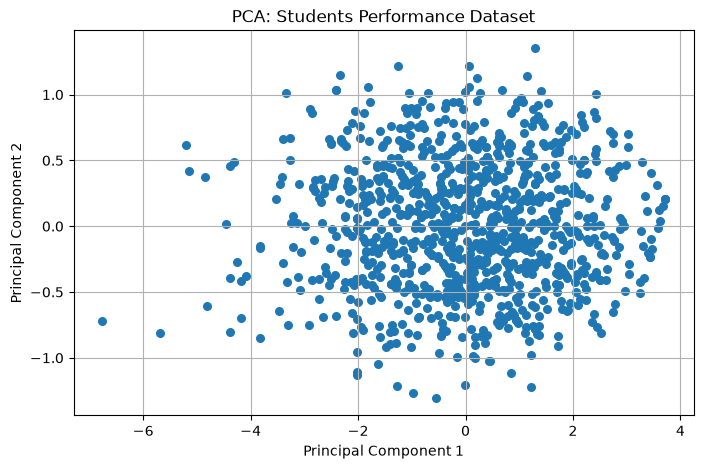

In [41]:
plt.figure(figsize=(8, 5))

plt.scatter(
    pca_df['PC1'],
    pca_df['PC2'],
    s=30
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA: Students Performance Dataset")
plt.grid(True)
plt.show()